In [1]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


Epoch 1/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - kl_loss: 5.0275 - loss: 179.3900 - reconstruction_loss: 174.3625
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - kl_loss: 4.6337 - loss: 163.7754 - reconstruction_loss: 159.1417
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - kl_loss: 4.9531 - loss: 164.4674 - reconstruction_loss: 159.5143
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - kl_loss: 5.0541 - loss: 171.0349 - reconstruction_loss: 165.9809
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - kl_loss: 5.0538 - loss: 165.3059 - reconstruction_loss: 160.2521
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - kl_loss: 5.2698 - loss: 162.2994 - reconstruction_loss: 157.0296
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - kl_loss: 5.3907 - loss: 160.2741 - reconstruction_loss: 154.8834
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 11ms/step - kl_loss: 5.6033 - loss: 156.6125 - reconstruction_loss: 151.0092
Epoch 9/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 

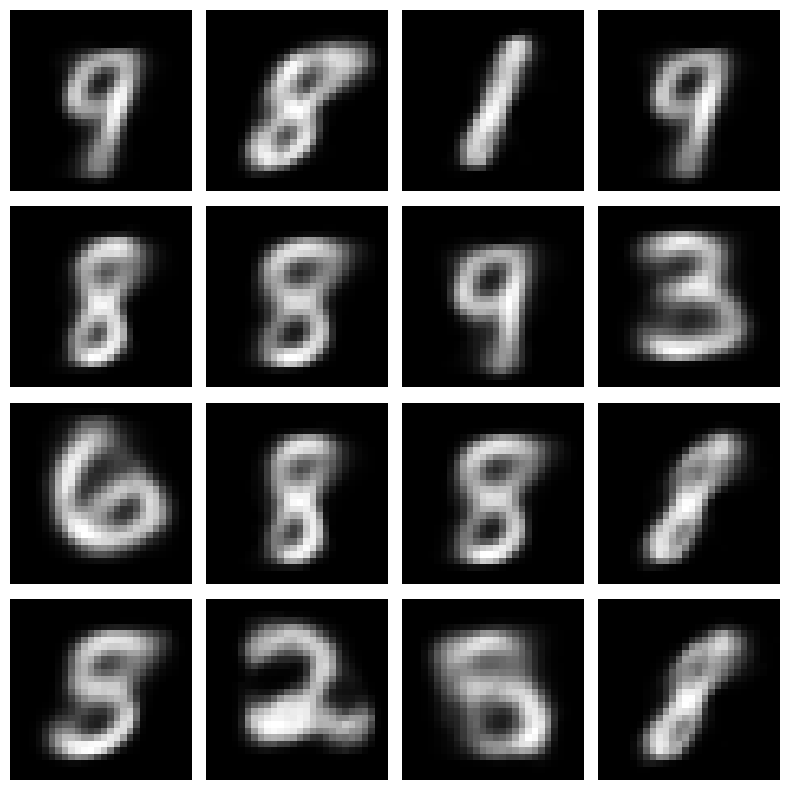

In [5]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# 1. PARAMETERS
# ============================================================

INPUT_DIM = 784
LATENT_DIM = 2
HIDDEN_DIM = 256
BATCH_SIZE = 128
EPOCHS = 20


# ============================================================
# 2. LOAD MNIST DATASET
# ============================================================

(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()


# ============================================================
# 3. NORMALIZE PIXELS
# ============================================================

x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0


# ============================================================
# 4. FLATTEN 28 × 28 IMAGE INTO 784 VALUES
# ============================================================

x_train = x_train.reshape(-1, INPUT_DIM)
x_test = x_test.reshape(-1, INPUT_DIM)


# ============================================================
# 5. CREATE TENSORFLOW DATASET
# ============================================================

train_dataset = tf.data.Dataset.from_tensor_slices(x_train)

train_dataset = train_dataset.shuffle(60000)

train_dataset = train_dataset.batch(BATCH_SIZE)


# ============================================================
# 6. ENCODER
# ============================================================

encoder_inputs = tf.keras.Input(
    shape=(INPUT_DIM,),
    name="encoder_input"
)

x = tf.keras.layers.Dense(
    HIDDEN_DIM,
    activation="relu"
)(encoder_inputs)

z_mean = tf.keras.layers.Dense(
    LATENT_DIM,
    name="z_mean"
)(x)

z_log_var = tf.keras.layers.Dense(
    LATENT_DIM,
    name="z_log_var"
)(x)


# ============================================================
# 7. REPARAMETERIZATION / SAMPLING
# ============================================================

def sampling(args):

    z_mean, z_log_var = args

    epsilon = tf.random.normal(
        shape=tf.shape(z_mean)
    )

    z = (
        z_mean
        + tf.exp(0.5 * z_log_var) * epsilon
    )

    return z


z = tf.keras.layers.Lambda(
    sampling,
    name="latent_vector"
)([z_mean, z_log_var])


# ============================================================
# 8. CREATE ENCODER
# ============================================================

encoder = tf.keras.Model(
    encoder_inputs,
    [z_mean, z_log_var, z],
    name="encoder"
)


# ============================================================
# 9. DECODER
# ============================================================

latent_inputs = tf.keras.Input(
    shape=(LATENT_DIM,),
    name="decoder_input"
)

x = tf.keras.layers.Dense(
    HIDDEN_DIM,
    activation="relu"
)(latent_inputs)

decoder_outputs = tf.keras.layers.Dense(
    INPUT_DIM,
    activation="sigmoid"
)(x)

decoder = tf.keras.Model(
    latent_inputs,
    decoder_outputs,
    name="decoder"
)


# ============================================================
# 10. VAE MODEL
# ============================================================

class VAE(tf.keras.Model):

    def __init__(
        self,
        encoder,
        decoder,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):

        with tf.GradientTape() as tape:

            # ----------------------------------------------
            # Encode input
            # ----------------------------------------------

            z_mean, z_log_var, z = self.encoder(data)

            # ----------------------------------------------
            # Decode latent vector
            # ----------------------------------------------

            reconstruction = self.decoder(z)

            # ----------------------------------------------
            # Reconstruction loss
            # ----------------------------------------------

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    -(
                        data * tf.math.log(
                            reconstruction + 1e-7
                        )
                        +
                        (1 - data) * tf.math.log(
                            1 - reconstruction + 1e-7
                        )
                    ),
                    axis=1
                )
            )

            # ----------------------------------------------
            # KL divergence
            # ----------------------------------------------

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1
                    + z_log_var
                    - tf.square(z_mean)
                    - tf.exp(z_log_var),
                    axis=1
                )
            )

            # ----------------------------------------------
            # Total loss
            # ----------------------------------------------

            total_loss = (
                reconstruction_loss
                + kl_loss
            )

        # ----------------------------------------------
        # Calculate gradients
        # ----------------------------------------------

        gradients = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        # ----------------------------------------------
        # Update weights
        # ----------------------------------------------

        self.optimizer.apply_gradients(
            zip(
                gradients,
                self.trainable_weights
            )
        )

        # ----------------------------------------------
        # Return losses
        # ----------------------------------------------

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }


# ============================================================
# 11. CREATE VAE
# ============================================================

vae = VAE(
    encoder,
    decoder
)


# ============================================================
# 12. COMPILE
# ============================================================

vae.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    )
)


# ============================================================
# 13. TRAIN VAE
# ============================================================

vae.fit(
    train_dataset,
    epochs=EPOCHS
)


# ============================================================
# 14. GENERATE NEW MNIST DIGITS
# ============================================================

number_of_digits = 16

random_latent_vectors = tf.random.normal(
    shape=(
        number_of_digits,
        LATENT_DIM
    )
)

generated_digits = decoder(
    random_latent_vectors
)


# ============================================================
# 15. DISPLAY GENERATED DIGITS
# ============================================================

plt.figure(
    figsize=(8, 8)
)

for i in range(number_of_digits):

    ax = plt.subplot(
        4,
        4,
        i + 1
    )

    plt.imshow(
        generated_digits[i].numpy().reshape(28, 28),
        cmap="gray"
    )

    plt.axis("off")

plt.tight_layout()
plt.show()

In [20]:
!pip install -q kaggle

In [21]:
import sys
!{sys.executable} -m pip install -q kaggle

In [22]:
import kaggle

print("Kaggle installed successfully!")


Authentication required to call the Kaggle API.

First, you will need a Kaggle account. You can sign up at
  https://www.kaggle.com/account/login

Recommended: log in with OAuth via a web-based authorization flow.
No token to manage; credentials are cached locally for you.
    kaggle auth login

If you'd rather not use OAuth, generate an API token at
  https://www.kaggle.com/settings/api  (click "Generate New Token" under "API")
and supply it to the CLI in one of these ways:

  Option A: Environment variable
    export KAGGLE_API_TOKEN=xxxxxxxxxxxxxx  # token copied from the settings UI

  Option B: API token file
    Save the token to ~/.kaggle/access_token
Kaggle installed successfully!


In [24]:
import os

os.environ["KAGGLE_API_TOKEN"] = "KGAT_22b12286ad6ed37be50be77523c4c4f0"

print("Kaggle authentication token set!")

Kaggle authentication token set!


In [25]:
!kaggle datasets download -d jessicali9530/celeba-dataset -p "C:\Users\HP\celeba"

Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other




  0%|          | 0.00/1.33G [00:00<?, ?B/s]
  0%|          | 1.00M/1.33G [00:01<35:11, 676kB/s]
  0%|          | 2.00M/1.33G [00:01<17:38, 1.35MB/s]
  0%|          | 3.00M/1.33G [00:01<11:03, 2.15MB/s]
  0%|          | 4.00M/1.33G [00:02<07:54, 3.00MB/s]
  0%|          | 5.00M/1.33G [00:02<06:50, 3.46MB/s]
  1%|          | 7.00M/1.33G [00:02<04:44, 5.00MB/s]
  1%|          | 8.00M/1.33G [00:02<04:36, 5.13MB/s]
  1%|          | 9.00M/1.33G [00:02<03:58, 5.94MB/s]
  1%|          | 10.0M/1.33G [00:02<03:45, 6.28MB/s]
  1%|          | 11.0M/1.33G [00:03<03:30, 6.73MB/s]
  1%|          | 12.0M/1.33G [00:03<03:21, 7.04MB/s]
  1%|          | 13.0M/1.33G [00:03<03:11, 7.38MB/s]
  1%|1         | 14.0M/1.33G [00:03<03:11, 7.39MB/s]
  1%|1         | 15.0M/1.33G [00:03<03:09, 7.45MB/s]
  1%|1         | 16.0M/1.33G [00:03<03:08, 7.49MB/s]
  1%|1         | 17.0M/1.33G [00:03<03:11, 7.36MB/s]
  1%|1         | 18.0M/1.33G [00:04<03:19, 7.05MB/s]
  1%|1         | 19.0M/1.33G [00:04<03:13, 7.26MB/s]
  

In [26]:
import zipfile
import os

zip_path = r"C:\Users\HP\celeba\celeba-dataset.zip"
extract_path = r"C:\Users\HP\celeba\data"

os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("CelebA extracted successfully!")

CelebA extracted successfully!


In [27]:
import os

for root, dirs, files in os.walk(r"C:\Users\HP\celeba\data"):
    jpg_files = [f for f in files if f.lower().endswith(".jpg")]

    if len(jpg_files) > 100:
        print("Image folder:", root)
        print("Number of images:", len(jpg_files))
        break

Image folder: C:\Users\HP\celeba\data\img_align_celeba\img_align_celeba
Number of images: 202599


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import os

# ============================================================
# 1. PARAMETERS
# ============================================================

IMAGE_SIZE = 28
CHANNELS = 3

INPUT_DIM = IMAGE_SIZE * IMAGE_SIZE * CHANNELS

LATENT_DIM = 2
HIDDEN_DIM = 256
BATCH_SIZE = 128
EPOCHS = 20


# ============================================================
# 2. LOAD CELEBRITY IMAGE FILES
# ============================================================

IMAGE_FOLDER = r"C:\Users\HP\celeba\data\img_align_celeba\img_align_celeba"

image_files = [
    os.path.join(IMAGE_FOLDER, file)
    for file in os.listdir(IMAGE_FOLDER)
    if file.lower().endswith(".jpg")
]

print("Number of images:", len(image_files))


# ============================================================
# 3. CREATE TENSORFLOW DATASET
# ============================================================

train_dataset = tf.data.Dataset.from_tensor_slices(
    image_files
)


# ============================================================
# 4. PREPROCESS IMAGES
# ============================================================

def preprocess_image(file_path):

    # Read image
    image = tf.io.read_file(file_path)

    # Decode JPEG
    image = tf.image.decode_jpeg(
        image,
        channels=3
    )

    # Resize to 28 × 28
    image = tf.image.resize(
        image,
        (IMAGE_SIZE, IMAGE_SIZE)
    )

    # Normalize pixels
    image = tf.cast(
        image,
        tf.float32
    ) / 255.0

    # Flatten 28 × 28 × 3
    image = tf.reshape(
        image,
        (INPUT_DIM,)
    )

    return image


train_dataset = train_dataset.map(
    preprocess_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

train_dataset = train_dataset.shuffle(
    10000
)

train_dataset = train_dataset.batch(
    BATCH_SIZE
)

train_dataset = train_dataset.prefetch(
    tf.data.AUTOTUNE
)


# ============================================================
# 5. ENCODER
# ============================================================

encoder_inputs = tf.keras.Input(
    shape=(INPUT_DIM,),
    name="encoder_input"
)

x = tf.keras.layers.Dense(
    HIDDEN_DIM,
    activation="relu"
)(encoder_inputs)

z_mean = tf.keras.layers.Dense(
    LATENT_DIM,
    name="z_mean"
)(x)

z_log_var = tf.keras.layers.Dense(
    LATENT_DIM,
    name="z_log_var"
)(x)


# ============================================================
# 6. REPARAMETERIZATION / SAMPLING
# ============================================================

def sampling(args):

    z_mean, z_log_var = args

    epsilon = tf.random.normal(
        shape=tf.shape(z_mean)
    )

    z = (
        z_mean
        + tf.exp(0.5 * z_log_var) * epsilon
    )

    return z


z = tf.keras.layers.Lambda(
    sampling,
    name="latent_vector"
)([
    z_mean,
    z_log_var
])


# ============================================================
# 7. CREATE ENCODER
# ============================================================

encoder = tf.keras.Model(
    encoder_inputs,
    [
        z_mean,
        z_log_var,
        z
    ],
    name="encoder"
)


# ============================================================
# 8. DECODER
# ============================================================

latent_inputs = tf.keras.Input(
    shape=(LATENT_DIM,),
    name="decoder_input"
)

x = tf.keras.layers.Dense(
    HIDDEN_DIM,
    activation="relu"
)(latent_inputs)

decoder_outputs = tf.keras.layers.Dense(
    INPUT_DIM,
    activation="sigmoid"
)(x)

decoder = tf.keras.Model(
    latent_inputs,
    decoder_outputs,
    name="decoder"
)


# ============================================================
# 9. VAE MODEL
# ============================================================

class VAE(tf.keras.Model):

    def __init__(
        self,
        encoder,
        decoder,
        **kwargs
    ):

        super().__init__(**kwargs)

        self.encoder = encoder
        self.decoder = decoder

    def train_step(self, data):

        with tf.GradientTape() as tape:

            # Encode input
            z_mean, z_log_var, z = self.encoder(data)

            # Decode latent vector
            reconstruction = self.decoder(z)

            # ----------------------------------------------
            # Reconstruction loss
            # ----------------------------------------------

            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    -(
                        data * tf.math.log(
                            reconstruction + 1e-7
                        )
                        +
                        (1 - data) * tf.math.log(
                            1 - reconstruction + 1e-7
                        )
                    ),
                    axis=1
                )
            )

            # ----------------------------------------------
            # KL divergence
            # ----------------------------------------------

            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1
                    + z_log_var
                    - tf.square(z_mean)
                    - tf.exp(z_log_var),
                    axis=1
                )
            )

            # ----------------------------------------------
            # Total loss
            # ----------------------------------------------

            total_loss = (
                reconstruction_loss
                + kl_loss
            )

        # Calculate gradients
        gradients = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        # Update weights
        self.optimizer.apply_gradients(
            zip(
                gradients,
                self.trainable_weights
            )
        )

        return {
            "loss": total_loss,
            "reconstruction_loss": reconstruction_loss,
            "kl_loss": kl_loss
        }


# ============================================================
# 10. CREATE VAE
# ============================================================

vae = VAE(
    encoder,
    decoder
)


# ============================================================
# 11. COMPILE
# ============================================================

vae.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    )
)


# ============================================================
# 12. TRAIN VAE
# ============================================================

vae.fit(
    train_dataset,
    epochs=EPOCHS
)


# ============================================================
# 13. GENERATE NEW CELEBRITY FACES
# ============================================================

number_of_images = 16

random_latent_vectors = tf.random.normal(
    shape=(
        number_of_images,
        LATENT_DIM
    )
)

generated_images = decoder(
    random_latent_vectors
)


# ============================================================
# 14. DISPLAY GENERATED CELEBRITY FACES
# ============================================================

plt.figure(
    figsize=(8, 8)
)

for i in range(number_of_images):

    ax = plt.subplot(
        4,
        4,
        i + 1
    )

    image = generated_images[i].numpy()

    image = image.reshape(
        IMAGE_SIZE,
        IMAGE_SIZE,
        CHANNELS
    )

    plt.imshow(image)

    plt.axis("off")

plt.tight_layout()
plt.show()